(125973, 43)
(22544, 43)
(125973, 123)
(22544, 123)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


{0: np.float64(0.9353087923020953), 1: np.float64(1.0743049633293535)}
Epoch 1/50
394/394 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.9706 - loss: 0.1211 - val_accuracy: 0.9906 - val_loss: 0.0619 - learning_rate: 0.0010
Epoch 2/50
394/394 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9878 - loss: 0.0672 - val_accuracy: 0.9913 - val_loss: 0.0551 - learning_rate: 0.0010
Epoch 3/50
394/394 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9892 - loss: 0.0585 - val_accuracy: 0.9913 - val_loss: 0.0501 - learning_rate: 0.0010
Epoch 4/50
394/394 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9896 - loss: 0.0533 - val_accuracy: 0.9917 - val_loss: 0.0449 - learning_rate: 0.0010
Epoch 5/50
394/394 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9900 - loss: 0.0492 - val_accuracy: 0.9909 - val_loss: 0.0417 - learning_rate: 0.0010
Epoch 6/50
394/394 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9901 - loss: 0.0451 - val_accuracy: 0.9925 - val_loss: 0.0400 - learning_rate: 0.0010
Epoch 7/50
394/

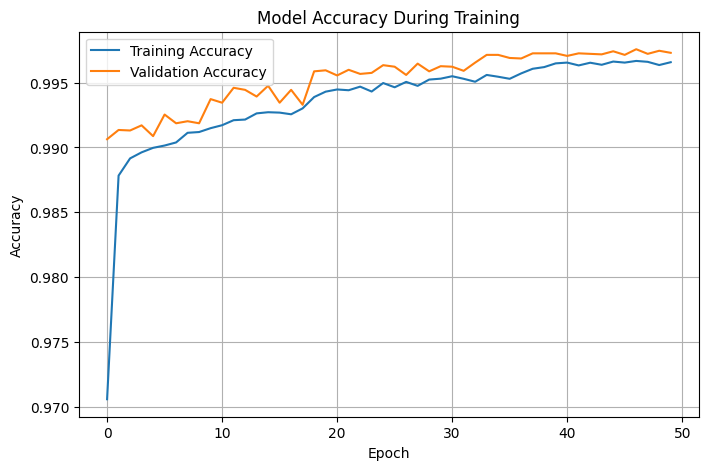

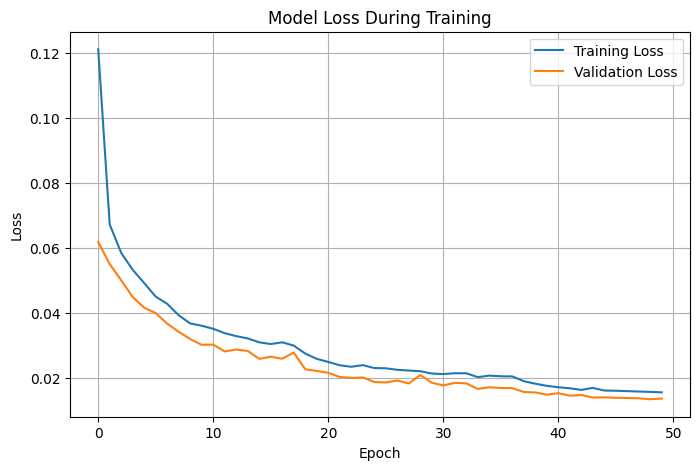

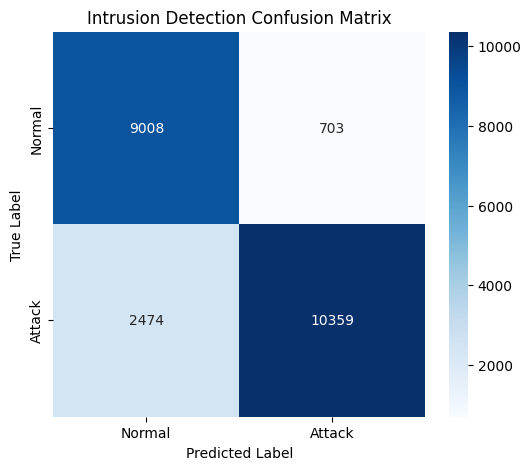

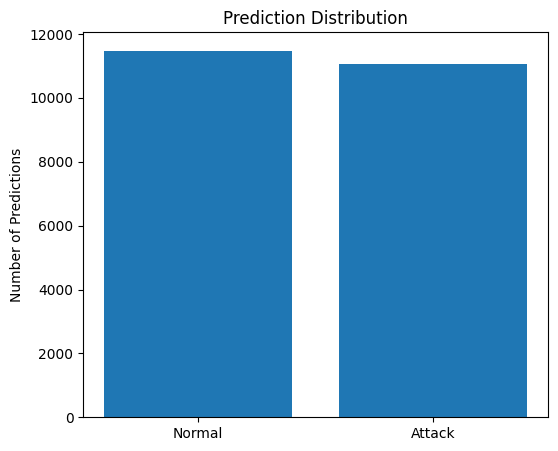

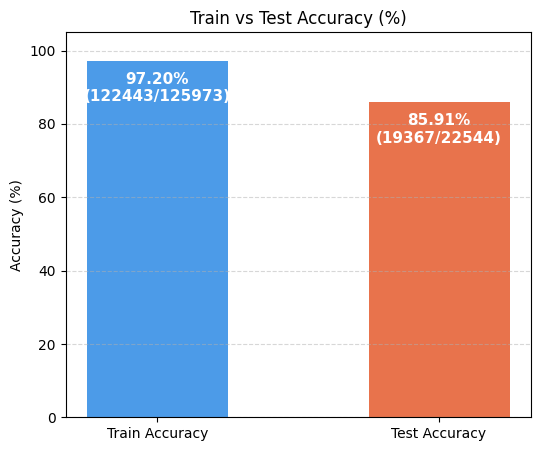

In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, roc_curve
from sklearn.utils import class_weight
import matplotlib.pyplot as plt
import seaborn as sns

columns = [
    'duration','protocol_type','service','flag','src_bytes','dst_bytes',
    'land','wrong_fragment','urgent','hot','num_failed_logins',
    'logged_in','num_compromised','root_shell','su_attempted',
    'num_root','num_file_creations','num_shells','num_access_files',
    'num_outbound_cmds','is_host_login','is_guest_login','count',
    'srv_count','serror_rate','srv_serror_rate','rerror_rate',
    'srv_rerror_rate','same_srv_rate','diff_srv_rate',
    'srv_diff_host_rate','dst_host_count','dst_host_srv_count',
    'dst_host_same_srv_rate','dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate','dst_host_srv_diff_host_rate',
    'dst_host_serror_rate','dst_host_srv_serror_rate',
    'dst_host_rerror_rate','dst_host_srv_rerror_rate',
    'label','difficulty'
]

train = pd.read_csv("KDDTrain+.txt", names=columns)
test  = pd.read_csv("KDDTest+.txt",  names=columns)

print(train.shape)
print(test.shape)

train['label'] = train['label'].apply(lambda x: 0 if x == 'normal' else 1)
test['label']  = test['label'].apply(lambda x: 0 if x == 'normal' else 1)

train.drop('difficulty', axis=1, inplace=True)
test.drop('difficulty',  axis=1, inplace=True)

train = pd.get_dummies(train)
test  = pd.get_dummies(test)
train, test = train.align(test, join='left', axis=1, fill_value=0)

print(train.shape)
print(test.shape)

X_train = train.drop('label', axis=1)
y_train = train['label']
X_test  = test.drop('label', axis=1)
y_test  = test['label']

scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

model = Sequential([
    Dense(256, activation='relu', kernel_regularizer=l2(1e-4),
          input_shape=(X_train.shape[1],)),
    BatchNormalization(),
    Dropout(0.4),

    Dense(128, activation='relu', kernel_regularizer=l2(1e-4)),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation='relu', kernel_regularizer=l2(1e-4)),
    BatchNormalization(),
    Dropout(0.3),

    Dense(32, activation='relu'),
    Dense(1,  activation='sigmoid')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = {0: weights[0], 1: weights[1]}
print(class_weights)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=256,
    validation_split=0.2,
    class_weight=class_weights,
    callbacks=[early_stop, lr_scheduler]
)

test_loss, test_accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", test_accuracy)
print("Test Loss:",     test_loss)

y_prob = model.predict(X_test)

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
youden_j  = tpr - fpr
best_idx  = np.argmax(youden_j)
best_thresh = thresholds[best_idx]
print(f"Optimal threshold (Youden J): {best_thresh:.4f}")

y_pred = (y_prob >= best_thresh).astype(int)

cm = confusion_matrix(y_test, y_pred)
print(cm)
print(classification_report(y_test, y_pred))

train_correct = int(np.sum(
    (model.predict(X_train) >= best_thresh).astype(int).flatten() == y_train.values
))
train_total   = len(y_train)
train_pct     = train_correct / train_total * 100

test_correct  = int(np.sum(y_pred.flatten() == y_test.values))
test_total    = len(y_test)
test_pct      = test_correct / test_total * 100

print("\n========== Accuracy Summary ==========")
print(f"Train Accuracy : {train_correct}/{train_total}  →  {train_pct:.2f}%")
print(f"Test  Accuracy : {test_correct}/{test_total}   →  {test_pct:.2f}%")
print("=======================================\n")

plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'],     label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy During Training')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'],     label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss During Training')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Normal', 'Attack'],
    yticklabels=['Normal', 'Attack']
)
plt.title('Intrusion Detection Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

labels = ['Normal', 'Attack']
values = np.bincount(y_pred.flatten())
plt.figure(figsize=(6, 5))
plt.bar(labels, values)
plt.title('Prediction Distribution')
plt.ylabel('Number of Predictions')
plt.show()

categories = ['Train Accuracy', 'Test Accuracy']
percentages = [train_pct, test_pct]
colors = ['#4C9BE8', '#E8734C']
plt.figure(figsize=(6, 5))
bars = plt.bar(categories, percentages, color=colors, width=0.5)
for bar, pct, correct, total in zip(bars, percentages,
                                    [train_correct, test_correct],
                                    [train_total,   test_total]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() - 3,
        f"{pct:.2f}%\n({correct}/{total})",
        ha='center', va='top', fontsize=11, color='white', fontweight='bold'
    )
plt.ylim(0, 105)
plt.title('Train vs Test Accuracy (%)')
plt.ylabel('Accuracy (%)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()